In [7]:
!pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("gaming_industry_trends.csv")

2. Valores faltantes por columna:
Game Title                 0
Genre                      0
Platform                   0
Release Year               0
Developer                  0
Revenue (Millions $)       0
Players (Millions)         0
Peak Concurrent Players    0
Metacritic Score           0
Esports Popularity         0
Trending Status            0
dtype: int64

Total de celdas vacías en el dataset: 0
 Visualización de datos faltantes con un mapa de calor


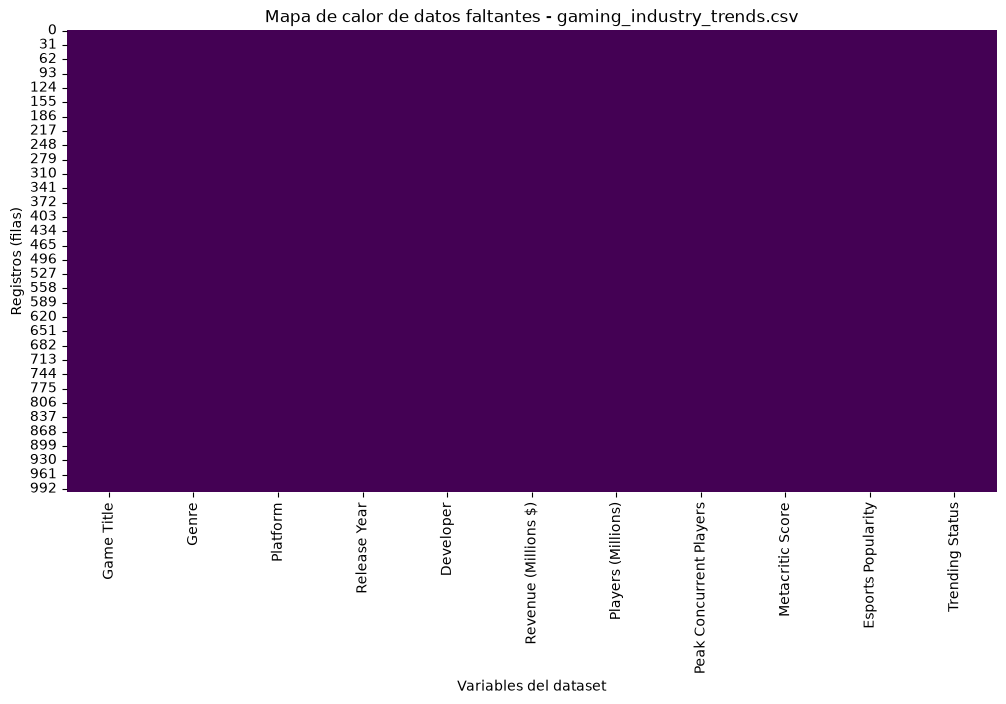

Valores nulos después del tratamiento:
0


In [9]:
print("2. Valores faltantes por columna:")
print(df.isnull().sum())

print("\nTotal de celdas vacías en el dataset:", df.isnull().sum().sum())


print(" Visualización de datos faltantes con un mapa de calor")
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Mapa de calor de datos faltantes - gaming_industry_trends.csv")
plt.xlabel("Variables del dataset")
plt.ylabel("Registros (filas)")
plt.show()

print("Valores nulos después del tratamiento:")
print(df.isnull().sum().sum())

**Justificación:** 
Al realizar la inspección cuantitativa y el mapa de calor de valores faltantes, se encontró que el conjunto de datos **`gaming_industry_trends.csv` cuenta con un total de 0 datos faltantes** en todas sus variables y registros. 

Dado que la integridad del dataset es completa (100% de los datos están presentes), **no es necesario aplicar técnicas de imputación** (como rellenar con la media, mediana o moda) **ni realizar eliminación de filas o columnas**. Esto garantiza que la estructura original de las observaciones se mantenga intacta para los siguientes pasos del análisis, evitando sesgos o pérdida de información.

In [10]:
print("4. Valores inconsistentes y duplicados")

duplicados_totales = df.duplicated().sum()
print(f"Cantidad de registros duplicados encontrados: {duplicados_totales}")
if duplicados_totales > 0:
    df = df.drop_duplicates()
    print("¡Registros duplicados eliminados exitosamente!")
else:
    print("No se encontraron registros duplicados en el dataset.")

    columnas_texto = df.select_dtypes(include=['object']).columns

print("\nColumnas de texto en el dataset:")
for col in columnas_texto:
    print(f"Columna: '{col}' ---> Valores únicos: {df[col].nunique()}")
    print(df[col].unique()[:10])

4. Valores inconsistentes y duplicados
Cantidad de registros duplicados encontrados: 0
No se encontraron registros duplicados en el dataset.

Columnas de texto en el dataset:
Columna: 'Game Title' ---> Valores únicos: 50
<StringArray>
[        'Neon Speed 5',        'Cyber Quest 5',     'Fantasy Rivals 1',
 'Warzone Chronicles 5',        'Cyber Quest 4', 'Warzone Chronicles 3',
         'Neon Speed 4',        'Cyber Quest 3', 'Warzone Chronicles 1',
    'Zombie Outbreak 4']
Length: 10, dtype: str
Columna: 'Genre' ---> Valores únicos: 10
<StringArray>
[  'Strategy',    'Shooter',     'Horror',        'RPG',     'Sports',
     'Action',  'Adventure',     'Racing',   'Fighting', 'Simulation']
Length: 10, dtype: str
Columna: 'Platform' ---> Valores únicos: 6
<StringArray>
['Xbox', 'Mobile', 'PC', 'Cross-Platform', 'Nintendo Switch', 'PlayStation']
Length: 6, dtype: str
Columna: 'Developer' ---> Valores únicos: 10
<StringArray>
[      'Capcom', 'Bandai Namco',    'Microsoft',           'EA'

/tmp/ipykernel_2282/1097991670.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  columnas_texto = df.select_dtypes(include=['object']).columns


**Justificación:** 
Al realizar la verificación de registros duplicados e inconsistencias en las variables de texto del conjunto de datos `gaming_industry_trends.csv`, se obtuvieron los siguientes hallazgos:

1. **Registros duplicados:** Se encontró un total de **0 registros duplicados**, lo que indica que cada fila del dataset representa una observación única y no fue necesario eliminar ninguna observación.
2. **Inconsistencias en texto:** Mediante la inspección de los valores únicos en las columnas categóricas (`Game title`, `Genre`, `Platform`, `Developer` y `Trending Status`), se comprobó que las categorías se encuentran debidamente estandarizadas. No se evidencian errores tipográficos, duplicidades por variaciones de mayúsculas/minúsculas ni espacios sobrantes, por lo que la estructura textual es completamente coherente para el análisis.

In [11]:
print("6. Filtrado y selección condicional de datos")

filtro_rising = df[df['Trending Status'] == 'Rising']
print(f"1. Juegos con tendencia 'Rising': {len(filtro_rising)}")


filtro_pc = df[df['Platform'] == 'PC']
print(f"2. Juegos en la plataforma PC: {len(filtro_pc)}")


filtro_strategy = df[df['Genre'] == 'Strategy']
print(f"3. Juegos del género Strategy: {len(filtro_strategy)}")


filtro_microsoft = df[df['Developer'] == 'Microsoft']
print(f"4. Juegos desarrollados por Microsoft: {len(filtro_microsoft)}")


filtro_stable = df[df['Trending Status'] == 'Stable']
print(f"5. Juegos con tendencia 'Stable': {len(filtro_stable)}")

6. Filtrado y selección condicional de datos
1. Juegos con tendencia 'Rising': 335
2. Juegos en la plataforma PC: 174
3. Juegos del género Strategy: 116
4. Juegos desarrollados por Microsoft: 106
5. Juegos con tendencia 'Stable': 339


**Justificación:** 
Se aplicaron 5 filtros básicos e independientes sobre el DataFrame para aislar categorías clave (como el estado de tendencia `Rising` y `Stable`, la plataforma `PC`, el género `Strategy` y el desarrollador `Microsoft`). Esto permite extraer métricas y porciones específicas de los datos de forma limpia y directa, facilitando consultas puntuales sobre el comportamiento del mercado de videojuegos sin requerir operaciones complejas.

8. Visualizaciónes
Gráfico 1: Distribución de juegos por Género (Gráfico de Barras)


/tmp/ipykernel_2282/2259417387.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Genre', palette='viridis', order=df['Genre'].value_counts().index)


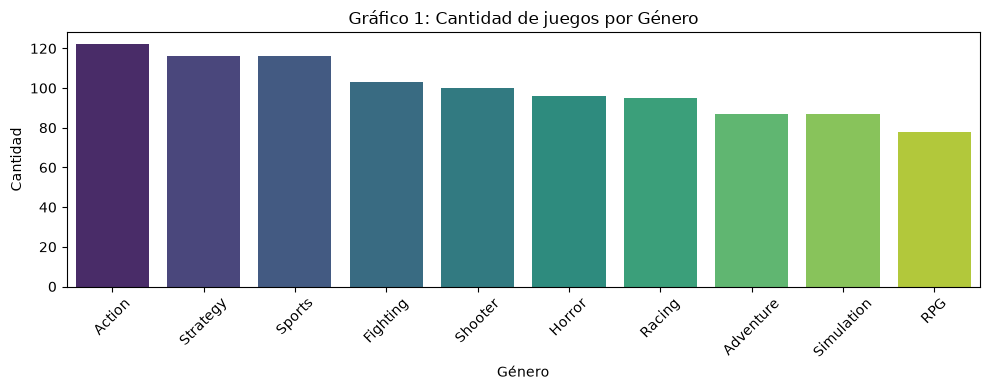

In [12]:
print("8. Visualizaciónes")

print("Gráfico 1: Distribución de juegos por Género (Gráfico de Barras)")
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='Genre', palette='viridis', order=df['Genre'].value_counts().index)
plt.title("Gráfico 1: Cantidad de juegos por Género")
plt.xlabel("Género")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



**Conclusión (Gráfico 1):** El diagrama de barras muestra claramente cuáles son los géneros con mayor representación en el mercado de videojuegos, permitiendo identificar las preferencias de desarrollo

Gráfico 2: Distribución de juegos por Plataforma (Gráfico de Conteo)


/tmp/ipykernel_2282/3900371950.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Platform', palette='magma', order=df['Platform'].value_counts().index)


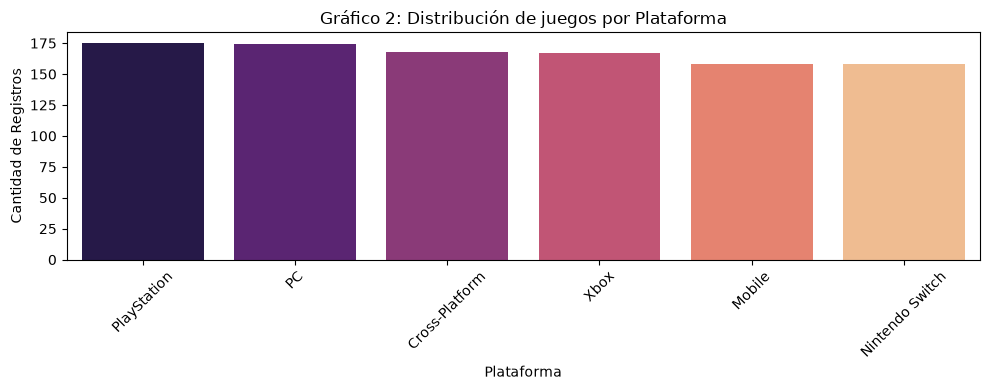

In [13]:
print("Gráfico 2: Distribución de juegos por Plataforma (Gráfico de Conteo)")

plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='Platform', palette='magma', order=df['Platform'].value_counts().index)
plt.title("Gráfico 2: Distribución de juegos por Plataforma")
plt.xlabel("Plataforma")
plt.ylabel("Cantidad de Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Conclusión (Gráfico 2):** Este gráfico permite visualizar qué plataformas tecnológicas albergan la mayor cantidad de títulos, evidenciando el alcance de cada una de ellas

Gráfico 3:Proporción del Estado de Tendencia (Gráfico Circular / Pie Chart)


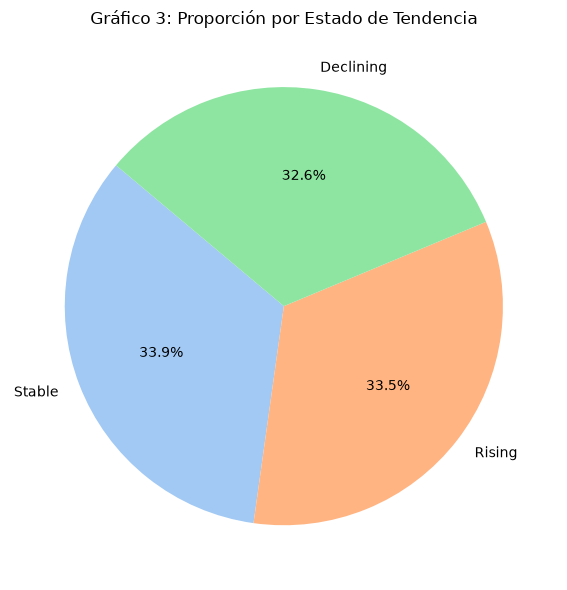

In [17]:
print("Gráfico 3:Proporción del Estado de Tendencia (Gráfico Circular / Pie Chart)")

plt.figure(figsize=(6, 6))
conteo_status = df['Trending Status'].value_counts()

plt.pie(
    conteo_status, 
    labels=conteo_status.index, 
    autopct='%1.1f%%', 
    colors=sns.color_palette('pastel'), 
    startangle=140
)
plt.title("Gráfico 3: Proporción por Estado de Tendencia")
plt.tight_layout()
plt.show()

**Conclusión (Gráfico 3):** La visualización expone el comportamiento general del mercado (cuántos títulos se encuentran estables, en ascenso o declive)

Gráfico 4: Cantidad de juegos por Desarrollador Principal


/tmp/ipykernel_2282/3502247734.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='Developer', palette='coolwarm', order=df['Developer'].value_counts().index[:10])


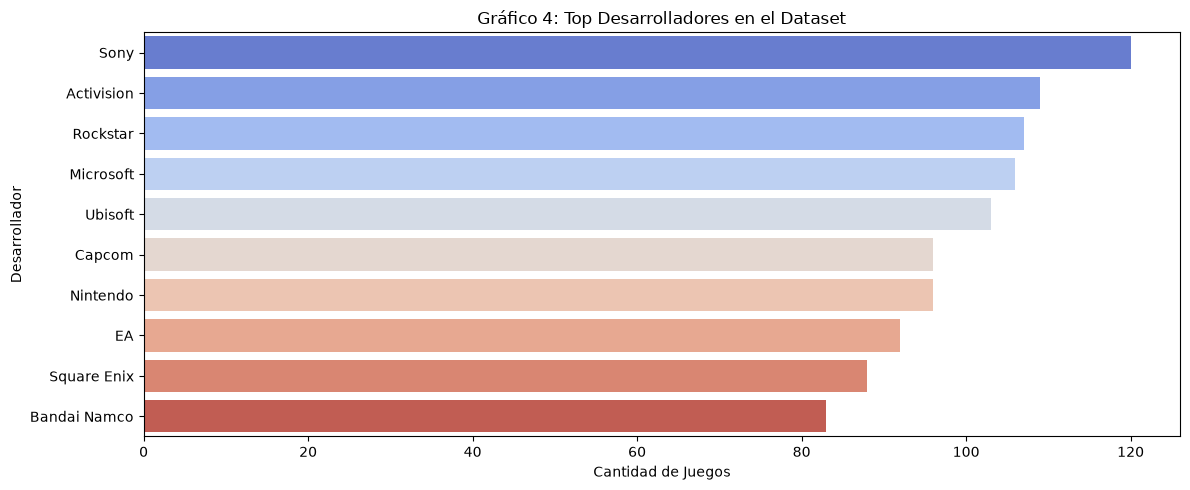

In [15]:
print("Gráfico 4: Cantidad de juegos por Desarrollador Principal")

plt.figure(figsize=(12, 5))
sns.countplot(data=df, y='Developer', palette='coolwarm', order=df['Developer'].value_counts().index[:10])
plt.title("Gráfico 4: Top Desarrolladores en el Dataset")
plt.xlabel("Cantidad de Juegos")
plt.ylabel("Desarrollador")
plt.tight_layout()
plt.show()

**Conclusión (Gráfico 4):** El gráfico de barras horizontales muestra los principales estudios o casas desarrolladoras con mayor presencia en el conjunto de datos

Gráfico 5: Relación entre Género y Estado de Tendencia


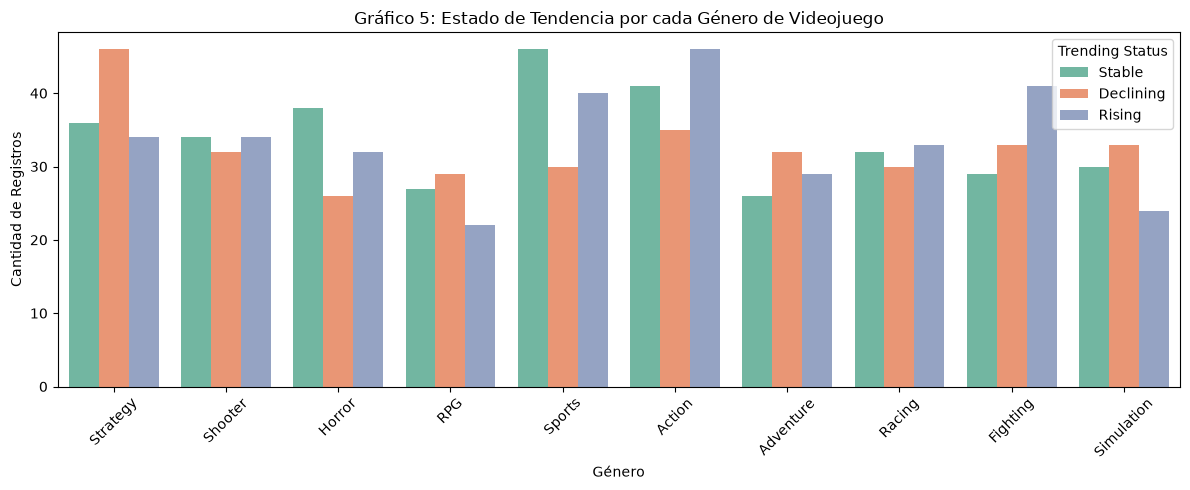

In [19]:
print("Gráfico 5: Relación entre Género y Estado de Tendencia")

plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='Genre', hue='Trending Status', palette='Set2')
plt.title("Gráfico 5: Estado de Tendencia por cada Género de Videojuego")
plt.xlabel("Género")
plt.ylabel("Cantidad de Registros")
plt.xticks(rotation=45)
plt.legend(title="Trending Status")
plt.tight_layout()
plt.show()



**Conclusión (Gráfico 5):** Este gráfico de barras agrupadas permite analizar de manera cruzada cómo se distribuyen los estados de tendencia (`Rising`, `Stable`, `Declining`) dentro de cada género de videojuego